Tidy Data, Data Characteristics

1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it
2. Evaluate if the data is good or not. Does it have enough samples?
3. How many input features does it have? Is it enough?
4. How many samples/observation does it have? Is it enough?
5. What are the datatypes does the dataset consist of?
6. How many columns have null values? If yes, which column, which rows
7. Which column is the feature, which is the target output?
8. Does it have missing values? If yes, which column, which row.
9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

​



In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Q1.

In [6]:
import pandas as pd

data = {
    "Name":["Henry","John","David","Holmes","Marvin","Simon","Robert","Trent"],
    "OverallGrade":["A","C","F","B","E","A",None,"C"],
    "Obedient":["Y","N","N",None,"N","Y","Y","Y"],
    "ResearchScore":[90,85,10,75,20,None,60,75],
    "ProjectScore":[85,51,17,71,30,79,59,33],
    "Recommend":["Yes","Yes","No","No","No","Yes","No","No"]
}
df = pd.DataFrame(data)
df

,Name,OverallGrade,Obedient,ResearchScore,ProjectScore,Recommend
0,Henry,A,Y,90.0,85,Yes
1,John,C,N,85.0,51,Yes
2,David,F,N,10.0,17,No
3,Holmes,B,None,75.0,71,No
4,Marvin,E,N,20.0,30,No
5,Simon,A,Y,NaN,79,Yes
6,Robert,None,Y,60.0,59,No
7,Trent,C,Y,75.0,33,No


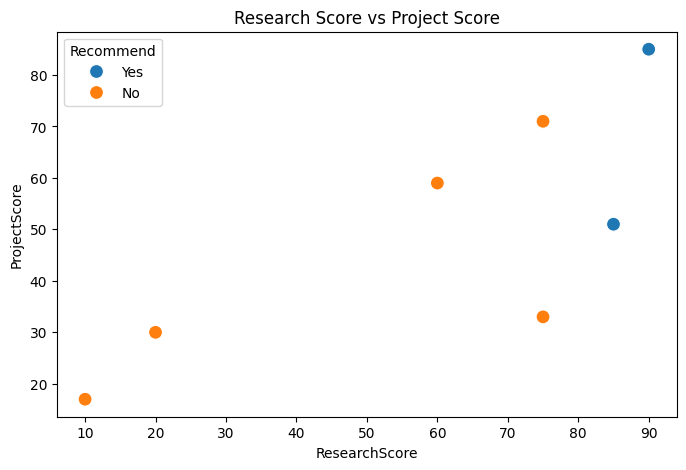

In [7]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='ResearchScore', y='ProjectScore', hue='Recommend', s=100)
plt.title('Research Score vs Project Score')
plt.show()

We use a scatter plot to visualize the relationship between ResearchScore and ProjectScore. Different colours represent different scholarship recommendation results. We can observe the distribution of students who get "Yes" or "No" recommendation.

Q4.

In [8]:
df.shape

(8, 6)

Q3.There are 4 input features. For a small tutorial demo, it is acceptable; for a real ML model, more features and samples are needed.

In [9]:
df.columns

Index(['Name', 'OverallGrade', 'Obedient', 'ResearchScore', 'ProjectScore',
       'Recommend'],
      dtype='object')

Q5.（object）：Name, OverallGrade, Obedient, Recommend
ResearchScore(float), ProjectScore(int)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Name           8 non-null      object 
 1   OverallGrade   7 non-null      object 
 2   Obedient       7 non-null      object 
 3   ResearchScore  7 non-null      float64
 4   ProjectScore   8 non-null      int64  
 5   Recommend      8 non-null      object 
dtypes: float64(1), int64(1), object(4)
memory usage: 516.0+ bytes


Q2.This dataset is clean and structured, but only has 8 rows of samples — it is too small for training a reliable machine learning model, it is only suitable for classroom demonstration.

In [11]:
df.describe

<bound method NDFrame.describe of      Name OverallGrade Obedient  ResearchScore  ProjectScore Recommend
0   Henry            A        Y           90.0            85       Yes
1    John            C        N           85.0            51       Yes
2   David            F        N           10.0            17        No
3  Holmes            B     None           75.0            71        No
4  Marvin            E        N           20.0            30        No
5   Simon            A        Y            NaN            79       Yes
6  Robert         None        Y           60.0            59        No
7   Trent            C        Y           75.0            33        No>

Q6.
There are 2 columns that contain null values in total:

1. The OverallGrade column has 1 missing value (on the row of student Robert, index 6)

2. The Obedient column has 1 missing value (on the row of student Holmes, index 3)


In [12]:
df.isnull().sum()

,0
Name,0
OverallGrade,1
Obedient,1
ResearchScore,1
ProjectScore,0
Recommend,0


Q7.Features: OverallGrade, Obedient, ResearchScore, ProjectScore.
Target output: Recommend. Name is only an ID and not a feature.

Q8.Yes, the dataset contains missing values.

• Index 3 (Holmes): Missing value in the Obedient column

• Index 6 (Robert): Missing value in the OverallGrade column

In [13]:
df[df.isnull().any(axis=1)]

,Name,OverallGrade,Obedient,ResearchScore,ProjectScore,Recommend
3,Holmes,B,None,75.0,71,No
5,Simon,A,Y,NaN,79,Yes
6,Robert,None,Y,60.0,59,No


Q9.It is a binary classification task. We want to predict the scholarship result (Recommend) from the student’s grade, obedience, research score and project score. The dataset is suitable for this task for learning purposes, but it has too few samples for practical prediction.